# Week 7 — Final Cross-Metric Comparison

## Objective

This notebook closes Week 7 by integrating the frozen results from the five
formal fidelity defects:

- Template Repetition
- Broken Timing
- Entity Inconsistency
- Missing Cross-Channel Reference
- Over-Polished Language

No defects are generated, no representations are refit, and no hypothesis
tests are rerun here.

The comparison integrates:

- C2ST, MMD, Energy, and Sinkhorn empirical power;
- Type I error calibration;
- representation displacement;
- Sinkhorn observed-minus-permutation-null behavior;
- Improved Precision and Recall support diagnostics;
- computational runtime;
- explicit blind spots and negative findings.

Improved Precision and Recall are descriptive support diagnostics and are not
treated as hypothesis-test power.

The purpose is not to identify a universally best metric. The goal is to
characterize the interaction between defect, representation, test design,
and diagnostic metric.

In [3]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from pathlib import Path
from scipy.sparse import load_npz
import importlib

import src.paths as paths
import src.io_utils as io_utils
importlib.reload(paths)
importlib.reload(io_utils)

from src.paths import get_project_paths
from src.io_utils import load_embedding_conditions,load_id_file

P=get_project_paths()
DATA_DIR=P["processed"]
RESULTS_DIR=P["results"]
W7=RESULTS_DIR/"week7"
OUT=W7/"comparison"
OUT.mkdir(parents=True,exist_ok=True)

DEFECTS=["Template Repetition","Broken Timing","Entity Inconsistency","Missing Cross-Channel","Over-Polished Language"]
SEVERITIES=[0.10,0.30,0.60]
METRICS=["C2ST","Energy","MMD","Sinkhorn"]

#### general helpers

In [4]:
def pick(*patterns,exclude=()):
    hits=[]
    for root in [W7,RESULTS_DIR]:
        for pattern in patterns: hits.extend(root.rglob(pattern))
    hits=[p for p in dict.fromkeys(hits) if not any(x.lower() in p.name.lower() for x in exclude)]
    if not hits: raise FileNotFoundError(patterns)
    return hits[0]

def canon_defect(x):
    m={"Missing Cross-Channel Reference":"Missing Cross-Channel","Missing Cross-Channel":"Missing Cross-Channel"}
    return m.get(str(x),str(x))

def norm_severity(x):
    x=float(x)
    return x/100 if x>1 else x

def normalize_power(df,defect):
    x=df.copy(); x.columns=[str(c).strip() for c in x.columns]
    if {"severity","metric","power"}.issubset(x.columns):
        out=x[["severity","metric","power"]].copy()
    else:
        aliases={"C2ST":["C2ST","c2st_power"],"Energy":["Energy","energy_power"],"MMD":["MMD","mmd_power"],"Sinkhorn":["Sinkhorn","sinkhorn_power"]}
        rows=[]
        for metric,cands in aliases.items():
            col=next((c for c in cands if c in x.columns),None)
            if col is not None:
                for _,r in x.iterrows(): rows.append({"severity":r["severity"],"metric":metric,"power":r[col]})
        out=pd.DataFrame(rows)
    out["severity"]=out["severity"].map(norm_severity); out["power"]=out["power"].astype(float); out["defect"]=defect
    return out[["defect","severity","metric","power"]]

def normalize_null(df,defect):
    x=df.copy(); x.columns=[str(c).strip() for c in x.columns]
    if {"metric","type_I_error"}.issubset(x.columns):
        out=x[["metric","type_I_error"]].copy()
        for c in ["mean_p_value","median_p_value"]:
            if c in x.columns: out[c]=x[c]
    else:
        rows=[]
        for metric,key in [("C2ST","c2st"),("Energy","energy"),("MMD","mmd"),("Sinkhorn","sinkhorn")]:
            cols=[c for c in x.columns if key in c.lower() and ("type" in c.lower() or "error" in c.lower())]
            if cols: rows.append({"metric":metric,"type_I_error":float(x[cols[0]].iloc[0])})
        out=pd.DataFrame(rows)
    out["defect"]=defect
    return out

In [5]:
# formal power - template and broken
def load_formal_power(summary_path,enriched_path,defect):
    base=normalize_power(pd.read_csv(summary_path),defect)
    base=base.loc[base["metric"]!="Sinkhorn"].copy()
    sink=pd.read_csv(enriched_path)
    sink["severity"]=sink["severity"].map(norm_severity)
    sink=sink.groupby("severity")["reject"].mean().reset_index(name="power")
    sink["metric"]="Sinkhorn"; sink["defect"]=defect
    return pd.concat([base,sink[["defect","severity","metric","power"]]],ignore_index=True)

template_power=load_formal_power(
    W7/"template_formal_power_summary.csv",
    W7/"template_formal_sinkhorn_power_runs_enriched.csv",
    "Template Repetition"
)

bt_power=load_formal_power(
    W7/"broken_timing_formal_power_summary.csv",
    W7/"broken_timing_formal_sinkhorn_power_runs_enriched.csv",
    "Broken Timing"
)

display(template_power.pivot(index="severity",columns="metric",values="power"))
display(bt_power.pivot(index="severity",columns="metric",values="power"))

metric,C2ST,Energy,MMD,Sinkhorn
severity,,,,
0.1,0.33,0.95,0.95,0.97
0.3,1.00,1.00,1.00,1.00
0.6,1.00,1.00,1.00,1.00


metric,C2ST,Energy,MMD,Sinkhorn
severity,,,,
0.1,0.025,0.975,0.975,0.33
0.3,0.835,1.000,1.000,0.94
0.6,1.000,1.000,1.000,1.00


In [6]:
# semantic power - entity, missing, over polished
entity_base=normalize_power(pd.read_csv(pick("*entity*power*summary*.csv",exclude=("sinkhorn",))),"Entity Inconsistency")
missing_base=normalize_power(pd.read_csv(pick("*missing*power*summary*.csv",exclude=("sinkhorn",))),"Missing Cross-Channel")
op_base=normalize_power(pd.read_csv(pick("*over_polished*power*summary*.csv",exclude=("sinkhorn",))),"Over-Polished Language")

entity_base=entity_base.loc[entity_base["metric"]!="Sinkhorn"]
missing_base=missing_base.loc[missing_base["metric"]!="Sinkhorn"]
op_base=op_base.loc[op_base["metric"]!="Sinkhorn"]

display(entity_base)
display(missing_base)
display(op_base)

,defect,severity,metric,power
0,Entity Inconsistency,0.1,C2ST,0.000
1,Entity Inconsistency,0.1,Energy,0.605
2,Entity Inconsistency,0.1,MMD,0.640
3,Entity Inconsistency,0.3,C2ST,0.025
4,Entity Inconsistency,0.3,Energy,1.000
5,Entity Inconsistency,0.3,MMD,1.000
6,Entity Inconsistency,0.6,C2ST,0.165
7,Entity Inconsistency,0.6,Energy,1.000
8,Entity Inconsistency,0.6,MMD,1.000


,defect,severity,metric,power
0,Missing Cross-Channel,0.1,C2ST,0.005
1,Missing Cross-Channel,0.1,Energy,0.140
2,Missing Cross-Channel,0.1,MMD,0.140
3,Missing Cross-Channel,0.3,C2ST,0.125
4,Missing Cross-Channel,0.3,Energy,0.550
5,Missing Cross-Channel,0.3,MMD,0.560
6,Missing Cross-Channel,0.6,C2ST,0.505
7,Missing Cross-Channel,0.6,Energy,0.995
8,Missing Cross-Channel,0.6,MMD,0.995


,defect,severity,metric,power
0,Over-Polished Language,0.1,C2ST,0.00
1,Over-Polished Language,0.1,Energy,0.87
2,Over-Polished Language,0.1,MMD,0.88
3,Over-Polished Language,0.3,C2ST,0.28
4,Over-Polished Language,0.3,Energy,1.00
5,Over-Polished Language,0.3,MMD,1.00
6,Over-Polished Language,0.6,C2ST,0.93
7,Over-Polished Language,0.6,Energy,1.00
8,Over-Polished Language,0.6,MMD,1.00


In [7]:
# semantic sinkhorn power
def sinkhorn_power_from_runs(path,defect):
    x=pd.read_csv(path); x["severity"]=x["severity"].map(norm_severity)
    out=x.groupby("severity")["reject"].mean().reset_index(name="power")
    out["metric"]="Sinkhorn"; out["defect"]=defect
    return out[["defect","severity","metric","power"]]

entity_sink_path=pick("*entity*sinkhorn*power*runs*.csv","*sinkhorn*entity*power*runs*.csv")
missing_sink_path=pick("*missing*sinkhorn*power*runs*.csv","*sinkhorn*missing*power*runs*.csv")
op_sink_path=pick("*over_polished*sinkhorn*power*runs*.csv","*sinkhorn*over_polished*power*runs*.csv")

entity_sink=sinkhorn_power_from_runs(entity_sink_path,"Entity Inconsistency")
missing_sink=sinkhorn_power_from_runs(missing_sink_path,"Missing Cross-Channel")
op_sink=sinkhorn_power_from_runs(op_sink_path,"Over-Polished Language")

In [8]:
# final power matrix
power=pd.concat([template_power,bt_power,entity_base,missing_base,op_base,entity_sink,missing_sink,op_sink],ignore_index=True)
power["defect"]=power["defect"].map(canon_defect)
power=power.drop_duplicates(["defect","severity","metric"],keep="last").sort_values(["defect","severity","metric"]).reset_index(drop=True)

print("Rows:",len(power),"Expected:",5*3*4)
display(power.head(15))

Rows: 60 Expected: 60


,defect,severity,metric,power
0,Broken Timing,0.1,C2ST,0.025
1,Broken Timing,0.1,Energy,0.975
2,Broken Timing,0.1,MMD,0.975
3,Broken Timing,0.1,Sinkhorn,0.330
4,Broken Timing,0.3,C2ST,0.835
5,Broken Timing,0.3,Energy,1.000
6,Broken Timing,0.3,MMD,1.000
7,Broken Timing,0.3,Sinkhorn,0.940
8,Broken Timing,0.6,C2ST,1.000
9,Broken Timing,0.6,Energy,1.000


In [9]:
power_matrix=power.pivot(index=["defect","severity"],columns="metric",values="power").reset_index()
power_matrix.columns.name=None
power_matrix=power_matrix[["defect","severity","C2ST","Energy","MMD","Sinkhorn"]]
display(power_matrix.round(3))

,defect,severity,C2ST,Energy,MMD,Sinkhorn
0,Broken Timing,0.1,0.025,0.975,0.975,0.330
1,Broken Timing,0.3,0.835,1.000,1.000,0.940
2,Broken Timing,0.6,1.000,1.000,1.000,1.000
3,Entity Inconsistency,0.1,0.000,0.605,0.640,0.045
4,Entity Inconsistency,0.3,0.025,1.000,1.000,0.025
5,Entity Inconsistency,0.6,0.165,1.000,1.000,0.090
6,Missing Cross-Channel,0.1,0.005,0.140,0.140,0.125
7,Missing Cross-Channel,0.3,0.125,0.550,0.560,0.310
8,Missing Cross-Channel,0.6,0.505,0.995,0.995,0.685
9,Over-Polished Language,0.1,0.000,0.870,0.880,0.130


## type 1 calibration 

In [10]:
## template and broken
template_null=normalize_null(pd.read_csv(W7/"template_formal_null_summary.csv"),"Template Repetition")
bt_null=normalize_null(pd.read_csv(W7/"broken_timing_formal_null_summary.csv"),"Broken Timing")

display(template_null)
display(bt_null)

,metric,type_I_error,mean_p_value,median_p_value,defect
0,C2ST,0.030,0.518960,0.539604,Template Repetition
1,Energy,0.045,0.520297,0.549505,Template Repetition
2,MMD,0.045,0.515248,0.549505,Template Repetition
3,Sinkhorn,0.045,0.537030,0.549505,Template Repetition


,metric,type_I_error,mean_p_value,median_p_value,defect
0,C2ST,0.035,0.569010,0.569307,Broken Timing
1,Energy,0.065,0.510248,0.500000,Broken Timing
2,MMD,0.055,0.513069,0.504950,Broken Timing
3,Sinkhorn,0.045,0.519554,0.514851,Broken Timing


In [13]:
# semantic mmd, c2st, enery nulls
def null_from_file(path,defect):
    x=pd.read_csv(path).copy()
    if {"metric","type_I_error"}.issubset(x.columns):
        out=x[["metric","type_I_error"]].copy()
        if "mean_p_value" in x.columns: out["mean_p_value"]=x["mean_p_value"]
        if "median_p_value" in x.columns: out["median_p_value"]=x["median_p_value"]
    elif {"metric","reject"}.issubset(x.columns):
        agg={"reject":"mean"}
        if "p_value" in x.columns: agg["p_value"]=["mean","median"]
        g=x.groupby("metric").agg(agg)
        if "p_value" in x.columns:
            g.columns=["type_I_error","mean_p_value","median_p_value"]
        else:
            g.columns=["type_I_error"]
        out=g.reset_index()
    else:
        raise ValueError(f"Unsupported null format: {path.name} | {x.columns.tolist()}")
    out["defect"]=defect
    return out

entity_null=null_from_file(
    RESULTS_DIR/"entity_inconsistency_clean_null.csv",
    "Entity Inconsistency"
)

missing_null=entity_null.copy()
missing_null["defect"]="Missing Cross-Channel"

op_null=null_from_file(
    RESULTS_DIR/"over_polished_semantic_null_summary.csv",
    "Over-Polished Language"
)

display(entity_null)
display(missing_null)
display(op_null)

,metric,type_I_error,mean_p_value,median_p_value,defect
0,C2ST,0.035,0.549234,0.539795,Entity Inconsistency
1,Energy,0.055,0.505050,0.534653,Entity Inconsistency
2,MMD,0.055,0.505743,0.534653,Entity Inconsistency


,metric,type_I_error,mean_p_value,median_p_value,defect
0,C2ST,0.035,0.549234,0.539795,Missing Cross-Channel
1,Energy,0.055,0.505050,0.534653,Missing Cross-Channel
2,MMD,0.055,0.505743,0.534653,Missing Cross-Channel


,metric,type_I_error,mean_p_value,defect
0,C2ST,0.050,0.540801,Over-Polished Language
1,Energy,0.045,0.524406,Over-Polished Language
2,MMD,0.050,0.520347,Over-Polished Language


In [12]:
csvs=list(dict.fromkeys(list(W7.rglob("*.csv"))+list(RESULTS_DIR.rglob("*.csv"))))

candidates=[]
for p in csvs:
    name=p.name.lower()
    if any(k in name for k in ["entity","missing","over_polished","semantic"]) and any(k in name for k in ["null","type","calib"]):
        candidates.append(p)

for p in candidates:
    print(p.relative_to(RESULTS_DIR))

week7/sinkhorn_missing_reference_null_center.csv
week7/sinkhorn_over_polished_paired_null_summary.csv
week7/sinkhorn_over_polished_paired_null_runs.csv
week7/sinkhorn_over_polished_null_center.csv
over_polished_semantic_null_summary.csv
over_polished_semantic_null.csv
entity_inconsistency_clean_null.csv


### Shared campaign-semantic null calibration

Entity Inconsistency and Missing Cross-Channel Reference use the same frozen
clean campaign MiniLM representation and the same hypothesis-test design.

Their clean-vs-clean null experiment is therefore representation-level rather
than defect-specific.

The Entity clean-null artifact is reused for Missing Cross-Channel rather than
running or inventing a second identical null calibration.

In [14]:
# semantic sinkhorn type 1
def sinkhorn_null_row(path,defects):
    x=pd.read_csv(path)
    col="type_I_error" if "type_I_error" in x.columns else "rejection_rate"
    value=float(x[col].iloc[0])
    return pd.DataFrame([{"defect":d,"metric":"Sinkhorn","type_I_error":value} for d in defects])

campaign_sink_null=pick("*sinkhorn*paired*formal*null*summary*.csv","*campaign*sinkhorn*null*summary*.csv")
op_sink_null=pick("*over_polished*sinkhorn*null*summary*.csv","*sinkhorn*over_polished*null*summary*.csv")

semantic_sink_null=pd.concat([
    sinkhorn_null_row(campaign_sink_null,["Entity Inconsistency","Missing Cross-Channel"]),
    sinkhorn_null_row(op_sink_null,["Over-Polished Language"])
],ignore_index=True)

In [15]:
# final calibration table 
null_table=pd.concat([
    template_null[["defect","metric","type_I_error"]],
    bt_null[["defect","metric","type_I_error"]],
    entity_null[["defect","metric","type_I_error"]],
    missing_null[["defect","metric","type_I_error"]],
    op_null[["defect","metric","type_I_error"]],
    semantic_sink_null
],ignore_index=True)

null_table["defect"]=null_table["defect"].map(canon_defect)
null_table=null_table.drop_duplicates(["defect","metric"],keep="last").sort_values(["defect","metric"]).reset_index(drop=True)

type1_matrix=null_table.pivot(index="defect",columns="metric",values="type_I_error")
display(type1_matrix.round(3))

metric,C2ST,Energy,MMD,Sinkhorn
defect,,,,
Broken Timing,0.035,0.065,0.055,0.045
Entity Inconsistency,0.035,0.055,0.055,0.065
Missing Cross-Channel,0.035,0.055,0.055,0.065
Over-Polished Language,0.050,0.045,0.050,0.050
Template Repetition,0.030,0.045,0.045,0.045


#### representation displacement

In [16]:
def load_affected(path,id_col):
    x=pd.read_csv(path)
    sev_col=next(c for c in x.columns if "severity" in c.lower() or "percent" in c.lower())
    x["_severity"]=x[sev_col].map(norm_severity)
    return {s:set(x.loc[np.isclose(x["_severity"],s),id_col].astype(str)) for s in SEVERITIES}

def displacement_summary(clean,conditions,ids,affected,defect,representation):
    clean=np.asarray(clean); ids=np.asarray(ids).astype(str); rows=[]
    for s in SEVERITIES:
        Q=np.asarray(conditions[s]); mask=np.array([x in affected[s] for x in ids])
        D=np.linalg.norm(Q-clean,axis=1)
        rows.append({"defect":defect,"severity":s,"representation":representation,
                     "mean_affected_displacement":D[mask].mean(),"std_affected_displacement":D[mask].std(),
                     "median_affected_displacement":np.median(D[mask]),"max_affected_displacement":D[mask].max(),
                     "mean_unaffected_displacement":D[~mask].mean(),"max_unaffected_displacement":D[~mask].max()})
    return pd.DataFrame(rows)

In [17]:
# template tf idf displacement
tpl_clean=load_npz(DATA_DIR/"template_tfidf_clean.npz").toarray().astype(np.float32)
tpl_cond={s:load_npz(DATA_DIR/f"template_tfidf_{int(s*100)}pct.npz").toarray().astype(np.float32) for s in SEVERITIES}
tpl_ids=pd.read_csv(DATA_DIR/"template_repetition_formal_eval_ids.csv")["message_id"].astype(str).to_numpy()
tpl_plan=pd.read_csv(DATA_DIR/"template_repetition_formal_plan.csv")
tpl_aff={s:set(tpl_plan.loc[np.isclose(tpl_plan["severity"].map(norm_severity),s),"message_id"].astype(str)) for s in SEVERITIES}

tpl_disp=displacement_summary(tpl_clean,tpl_cond,tpl_ids,tpl_aff,"Template Repetition","TF-IDF 5000D")
display(tpl_disp)

,defect,severity,representation,mean_affected_displacement,std_affected_displacement,median_affected_displacement,max_affected_displacement,mean_unaffected_displacement,max_unaffected_displacement
0,Template Repetition,0.1,TF-IDF 5000D,1.387332,0.081486,1.414214,1.414214,0.0,0.0
1,Template Repetition,0.3,TF-IDF 5000D,1.400401,0.050059,1.414214,1.414214,0.0,0.0
2,Template Repetition,0.6,TF-IDF 5000D,1.399654,0.049414,1.414214,1.414214,0.0,0.0


In [18]:
# broken t structural displacement
bt_disp=pd.read_csv(W7/"broken_timing_formal_representation_response.csv")
bt_disp["severity"]=bt_disp["severity"].map(norm_severity)
bt_disp=bt_disp.rename(columns={
    "mean_affected_distance":"mean_affected_displacement",
    "std_affected_distance":"std_affected_displacement",
    "median_affected_distance":"median_affected_displacement",
    "max_affected_distance":"max_affected_displacement",
    "mean_unaffected_distance":"mean_unaffected_displacement",
    "max_unaffected_distance":"max_unaffected_displacement"
})
bt_disp["defect"]="Broken Timing"; bt_disp["representation"]="Structural 13D"
display(bt_disp)

,severity,n_affected,mean_affected_displacement,std_affected_displacement,median_affected_displacement,mean_unaffected_displacement,max_unaffected_displacement,defect,representation
0,0.1,30,1.507845,0.595198,1.463477,0.0,0.0,Broken Timing,Structural 13D
1,0.3,90,1.614294,0.742963,1.561982,0.0,0.0,Broken Timing,Structural 13D
2,0.6,180,1.624370,0.712970,1.585908,0.0,0.0,Broken Timing,Structural 13D


In [19]:
# entity
entity=load_embedding_conditions(DATA_DIR,"entity",(10,30,60))
entity_ids=np.asarray(load_id_file(DATA_DIR,"entity_embedding_campaign_ids.csv","campaign_id")).astype(str)
entity_aff=load_affected(DATA_DIR/"entity_inconsistency_affected_campaign_ids.csv","campaign_id")

entity_disp=displacement_summary(
    entity["clean"],{s:entity[s] for s in SEVERITIES},entity_ids,entity_aff,
    "Entity Inconsistency","Campaign MiniLM 384D"
)

display(entity_disp)

,defect,severity,representation,mean_affected_displacement,std_affected_displacement,median_affected_displacement,max_affected_displacement,mean_unaffected_displacement,max_unaffected_displacement
0,Entity Inconsistency,0.1,Campaign MiniLM 384D,0.063403,0.022338,0.062811,0.122291,0.0,0.0
1,Entity Inconsistency,0.3,Campaign MiniLM 384D,0.059693,0.027085,0.054587,0.220437,0.0,0.0
2,Entity Inconsistency,0.6,Campaign MiniLM 384D,0.058461,0.024268,0.054144,0.220437,0.0,0.0


In [20]:
# missing cross
missing=load_embedding_conditions(DATA_DIR,"missing_reference",(10,30,60))
missing_ids=np.asarray(load_id_file(DATA_DIR,"missing_reference_embedding_campaign_ids.csv","campaign_id")).astype(str)
missing_aff=load_affected(DATA_DIR/"missing_reference_affected_campaign_ids.csv","campaign_id")

missing_disp=displacement_summary(
    missing["clean"],{s:missing[s] for s in SEVERITIES},missing_ids,missing_aff,
    "Missing Cross-Channel","Campaign MiniLM 384D"
)

display(missing_disp)

,defect,severity,representation,mean_affected_displacement,std_affected_displacement,median_affected_displacement,max_affected_displacement,mean_unaffected_displacement,max_unaffected_displacement
0,Missing Cross-Channel,0.1,Campaign MiniLM 384D,0.159332,0.116056,0.128931,0.521489,0.0,0.0
1,Missing Cross-Channel,0.3,Campaign MiniLM 384D,0.136995,0.086208,0.115084,0.521489,0.0,0.0
2,Missing Cross-Channel,0.6,Campaign MiniLM 384D,0.140151,0.084180,0.118751,0.521489,0.0,0.0


In [21]:
# overpolished 
op=load_embedding_conditions(DATA_DIR,"over_polished",(10,30,60))
op_ids=np.asarray(load_id_file(DATA_DIR,"over_polished_embedding_message_ids.csv","message_id")).astype(str)
op_aff=load_affected(DATA_DIR/"over_polished_affected_message_ids.csv","message_id")

op_disp=displacement_summary(
    op["clean"],{s:op[s] for s in SEVERITIES},op_ids,op_aff,
    "Over-Polished Language","Message MiniLM 384D"
)

display(op_disp)

,defect,severity,representation,mean_affected_displacement,std_affected_displacement,median_affected_displacement,max_affected_displacement,mean_unaffected_displacement,max_unaffected_displacement
0,Over-Polished Language,0.1,Message MiniLM 384D,0.189858,0.093430,0.164287,0.380945,0.0,0.0
1,Over-Polished Language,0.3,Message MiniLM 384D,0.202803,0.156932,0.166639,1.086167,0.0,0.0
2,Over-Polished Language,0.6,Message MiniLM 384D,0.206644,0.159206,0.166639,1.114274,0.0,0.0


In [22]:
# combined displacement 
disp_cols=["defect","severity","representation","mean_affected_displacement","std_affected_displacement","median_affected_displacement","max_affected_displacement","mean_unaffected_displacement","max_unaffected_displacement"]

displacement=pd.concat([
    tpl_disp[disp_cols],
    bt_disp.reindex(columns=disp_cols),
    entity_disp[disp_cols],
    missing_disp[disp_cols],
    op_disp[disp_cols]
],ignore_index=True)

display(displacement.round(6))

,defect,severity,representation,mean_affected_displacement,std_affected_displacement,median_affected_displacement,max_affected_displacement,mean_unaffected_displacement,max_unaffected_displacement
0,Template Repetition,0.1,TF-IDF 5000D,1.387332,0.081486,1.414214,1.414214,0.0,0.0
1,Template Repetition,0.3,TF-IDF 5000D,1.400401,0.050059,1.414214,1.414214,0.0,0.0
2,Template Repetition,0.6,TF-IDF 5000D,1.399654,0.049414,1.414214,1.414214,0.0,0.0
3,Broken Timing,0.1,Structural 13D,1.507846,0.595198,1.463477,NaN,0.0,0.0
4,Broken Timing,0.3,Structural 13D,1.614294,0.742963,1.561982,NaN,0.0,0.0
5,Broken Timing,0.6,Structural 13D,1.624370,0.712970,1.585908,NaN,0.0,0.0
6,Entity Inconsistency,0.1,Campaign MiniLM 384D,0.063403,0.022338,0.062811,0.122291,0.0,0.0
7,Entity Inconsistency,0.3,Campaign MiniLM 384D,0.059693,0.027085,0.054587,0.220437,0.0,0.0
8,Entity Inconsistency,0.6,Campaign MiniLM 384D,0.058461,0.024268,0.054144,0.220437,0.0,0.0
9,Missing Cross-Channel,0.1,Campaign MiniLM 384D,0.159332,0.116056,0.128931,0.521489,0.0,0.0


## Representation displacement interpretation

Representation displacement is reported only within each frozen
representation.

Raw distances must not be compared directly across TF-IDF, structural
features, campaign MiniLM, and message MiniLM because the feature spaces,
dimensionalities, normalization schemes, and geometries differ.

The relevant comparison is whether displacement changes with prevalence and
how that response relates to downstream metric detectability within each
defect.

#### sinkhorn observed minus null

In [23]:
def sinkhorn_gap_from_runs(path,defect):
    x=pd.read_csv(path); x["severity"]=x["severity"].map(norm_severity)
    if "obs_minus_null" not in x.columns: x["obs_minus_null"]=x["statistic"]-x["null_mean"]
    out=x.groupby("severity").agg(
        sinkhorn_mean_statistic=("statistic","mean"),
        sinkhorn_mean_null=("null_mean","mean"),
        sinkhorn_obs_minus_null=("obs_minus_null","mean"),
        sinkhorn_obs_minus_null_std=("obs_minus_null","std"),
        sinkhorn_power=("reject","mean")
    ).reset_index()
    out["defect"]=defect
    return out

template_gap=sinkhorn_gap_from_runs(W7/"template_formal_sinkhorn_power_runs_enriched.csv","Template Repetition")
bt_gap=sinkhorn_gap_from_runs(W7/"broken_timing_formal_sinkhorn_power_runs_enriched.csv","Broken Timing")
entity_gap=sinkhorn_gap_from_runs(entity_sink_path,"Entity Inconsistency")
missing_gap=sinkhorn_gap_from_runs(missing_sink_path,"Missing Cross-Channel")
op_gap=sinkhorn_gap_from_runs(op_sink_path,"Over-Polished Language")

sink_gap=pd.concat([template_gap,bt_gap,entity_gap,missing_gap,op_gap],ignore_index=True)
sink_gap=sink_gap.sort_values(["defect","severity"]).reset_index(drop=True)

display(sink_gap.round(6))

,severity,sinkhorn_mean_statistic,sinkhorn_mean_null,sinkhorn_obs_minus_null,sinkhorn_obs_minus_null_std,sinkhorn_power,defect
0,0.1,0.132371,0.132156,0.000215,0.000499,0.330,Broken Timing
1,0.3,0.465046,0.445885,0.019161,0.014299,0.940,Broken Timing
2,0.6,0.937028,0.868656,0.068373,0.027331,1.000,Broken Timing
3,0.1,0.000230,0.000230,0.000000,0.000000,0.045,Entity Inconsistency
4,0.3,0.000646,0.000646,0.000000,0.000000,0.025,Entity Inconsistency
5,0.6,0.001198,0.001198,0.000000,0.000000,0.090,Entity Inconsistency
6,0.1,0.001771,0.001683,0.000088,0.000158,0.125,Missing Cross-Channel
7,0.3,0.003714,0.003564,0.000150,0.000214,0.310,Missing Cross-Channel
8,0.6,0.007810,0.007106,0.000704,0.000668,0.685,Missing Cross-Channel
9,0.1,0.002211,0.002211,0.000000,0.000000,0.130,Over-Polished Language


In [24]:
# validation against power 
sink_check=power.loc[power["metric"]=="Sinkhorn",["defect","severity","power"]].merge(
    sink_gap[["defect","severity","sinkhorn_power"]],on=["defect","severity"]
)
sink_check["difference"]=sink_check["power"]-sink_check["sinkhorn_power"]

display(sink_check)
print("Max Sinkhorn power difference:",np.abs(sink_check["difference"]).max())

,defect,severity,power,sinkhorn_power,difference
0,Broken Timing,0.1,0.330,0.330,0.0
1,Broken Timing,0.3,0.940,0.940,0.0
2,Broken Timing,0.6,1.000,1.000,0.0
3,Entity Inconsistency,0.1,0.045,0.045,0.0
4,Entity Inconsistency,0.3,0.025,0.025,0.0
5,Entity Inconsistency,0.6,0.090,0.090,0.0
6,Missing Cross-Channel,0.1,0.125,0.125,0.0
7,Missing Cross-Channel,0.3,0.310,0.310,0.0
8,Missing Cross-Channel,0.6,0.685,0.685,0.0
9,Over-Polished Language,0.1,0.130,0.130,0.0


Max Sinkhorn power difference: 0.0


#### improved precision and recall

In [25]:
ipr=pd.read_csv(W7/"ipr_five_defects_summary.csv")
ipr["defect"]=ipr["defect"].map(canon_defect)
ipr["severity"]=ipr["severity"].map(norm_severity)

ipr=ipr[[
    "defect","severity",
    "mean_precision","mean_recall",
    "matched_precision","matched_recall",
    "precision_loss_vs_matched","recall_loss_vs_matched"
]].sort_values(["defect","severity"]).reset_index(drop=True)

display(ipr.round(4))

,defect,severity,mean_precision,mean_recall,matched_precision,matched_recall,precision_loss_vs_matched,recall_loss_vs_matched
0,Broken Timing,0.1,0.9186,0.9254,0.9224,0.9304,0.0038,0.0049
1,Broken Timing,0.3,0.9050,0.9241,0.9224,0.9304,0.0174,0.0062
2,Broken Timing,0.6,0.8896,0.9053,0.9224,0.9304,0.0329,0.0250
3,Entity Inconsistency,0.1,0.8667,0.8560,0.8542,0.8610,-0.0124,0.0049
4,Entity Inconsistency,0.3,0.8659,0.8543,0.8542,0.8610,-0.0116,0.0066
5,Entity Inconsistency,0.6,0.8731,0.8467,0.8542,0.8610,-0.0188,0.0142
6,Missing Cross-Channel,0.1,0.8687,0.8532,0.8542,0.8610,-0.0144,0.0078
7,Missing Cross-Channel,0.3,0.8762,0.8426,0.8542,0.8610,-0.0220,0.0183
8,Missing Cross-Channel,0.6,0.8866,0.8095,0.8542,0.8610,-0.0323,0.0514
9,Over-Polished Language,0.1,0.8722,0.8776,0.8766,0.8736,0.0044,-0.0040


## Improved Precision and Recall

Improved Precision and Recall are retained as support diagnostics.

They are not permutation tests and therefore should not be placed in the same
"power" column as C2ST, MMD, Energy, or Sinkhorn.

Precision describes how much of the defective distribution remains inside
the estimated clean support.

Recall describes how much of the clean support remains covered by the
defective distribution.

The matched clean-clean baseline is reported because finite-sample k-NN
manifold estimation does not produce a perfect value of 1.0 even under
matched clean distributions.

#### runtime 

In [26]:
def runtime_from_runs(path,defect,default_metric=None):
    x=pd.read_csv(path)
    if "metric" not in x.columns:
        if default_metric is None: return pd.DataFrame()
        x["metric"]=default_metric
    if "runtime_seconds" not in x.columns: return pd.DataFrame()
    return x.groupby("metric")["runtime_seconds"].agg(["mean","std","median"]).reset_index().rename(
        columns={"mean":"mean_runtime_seconds","std":"std_runtime_seconds","median":"median_runtime_seconds"}
    ).assign(defect=defect)

tpl_runtime=runtime_from_runs(W7/"template_formal_power_runs.csv","Template Repetition")
bt_runtime=runtime_from_runs(W7/"broken_timing_formal_power_runs.csv","Broken Timing")

In [27]:
# semantic base runtime
entity_runs=pick("*entity*power*runs*.csv",exclude=("sinkhorn",))
missing_runs=pick("*missing*power*runs*.csv",exclude=("sinkhorn",))
op_runs=pick("*over_polished*power*runs*.csv",exclude=("sinkhorn",))

entity_runtime=runtime_from_runs(entity_runs,"Entity Inconsistency")
missing_runtime=runtime_from_runs(missing_runs,"Missing Cross-Channel")
op_runtime=runtime_from_runs(op_runs,"Over-Polished Language")

FileNotFoundError: ('*entity*power*runs*.csv',)

In [ ]:
# semantic sinkhorn runtime 
entity_sink_runtime=runtime_from_runs(entity_sink_path,"Entity Inconsistency","Sinkhorn")
missing_sink_runtime=runtime_from_runs(missing_sink_path,"Missing Cross-Channel","Sinkhorn")
op_sink_runtime=runtime_from_runs(op_sink_path,"Over-Polished Language","Sinkhorn")

runtime_table=pd.concat([
    tpl_runtime,bt_runtime,
    entity_runtime,missing_runtime,op_runtime,
    entity_sink_runtime,missing_sink_runtime,op_sink_runtime
],ignore_index=True)

runtime_table=runtime_table.drop_duplicates(["defect","metric"],keep="last").sort_values(["defect","metric"]).reset_index(drop=True)
display(runtime_table.round(4))

In [28]:
# master matrix
power_wide=power.pivot(index=["defect","severity"],columns="metric",values="power").reset_index()
power_wide.columns.name=None
power_wide=power_wide.rename(columns={m:f"{m}_power" for m in METRICS})

master=power_wide.merge(
    displacement[["defect","severity","representation","mean_affected_displacement"]],
    on=["defect","severity"],how="left"
)

master=master.merge(
    sink_gap[["defect","severity","sinkhorn_mean_statistic","sinkhorn_mean_null","sinkhorn_obs_minus_null"]],
    on=["defect","severity"],how="left"
)

master=master.merge(ipr,on=["defect","severity"],how="left")
master=master.sort_values(["defect","severity"]).reset_index(drop=True)

display(master.round(4))

,defect,severity,C2ST_power,Energy_power,MMD_power,Sinkhorn_power,representation,mean_affected_displacement,sinkhorn_mean_statistic,sinkhorn_mean_null,sinkhorn_obs_minus_null,mean_precision,mean_recall,matched_precision,matched_recall,precision_loss_vs_matched,recall_loss_vs_matched
0,Broken Timing,0.1,0.025,0.975,0.975,0.330,Structural 13D,1.5078,0.1324,0.1322,0.0002,0.9186,0.9254,0.9224,0.9304,0.0038,0.0049
1,Broken Timing,0.3,0.835,1.000,1.000,0.940,Structural 13D,1.6143,0.4650,0.4459,0.0192,0.9050,0.9241,0.9224,0.9304,0.0174,0.0062
2,Broken Timing,0.6,1.000,1.000,1.000,1.000,Structural 13D,1.6244,0.9370,0.8687,0.0684,0.8896,0.9053,0.9224,0.9304,0.0329,0.0250
3,Entity Inconsistency,0.1,0.000,0.605,0.640,0.045,Campaign MiniLM 384D,0.0634,0.0002,0.0002,0.0000,0.8667,0.8560,0.8542,0.8610,-0.0124,0.0049
4,Entity Inconsistency,0.3,0.025,1.000,1.000,0.025,Campaign MiniLM 384D,0.0597,0.0006,0.0006,0.0000,0.8659,0.8543,0.8542,0.8610,-0.0116,0.0066
5,Entity Inconsistency,0.6,0.165,1.000,1.000,0.090,Campaign MiniLM 384D,0.0585,0.0012,0.0012,0.0000,0.8731,0.8467,0.8542,0.8610,-0.0188,0.0142
6,Missing Cross-Channel,0.1,0.005,0.140,0.140,0.125,Campaign MiniLM 384D,0.1593,0.0018,0.0017,0.0001,0.8687,0.8532,0.8542,0.8610,-0.0144,0.0078
7,Missing Cross-Channel,0.3,0.125,0.550,0.560,0.310,Campaign MiniLM 384D,0.1370,0.0037,0.0036,0.0001,0.8762,0.8426,0.8542,0.8610,-0.0220,0.0183
8,Missing Cross-Channel,0.6,0.505,0.995,0.995,0.685,Campaign MiniLM 384D,0.1402,0.0078,0.0071,0.0007,0.8866,0.8095,0.8542,0.8610,-0.0323,0.0514
9,Over-Polished Language,0.1,0.000,0.870,0.880,0.130,Message MiniLM 384D,0.1899,0.0022,0.0022,0.0000,0.8722,0.8776,0.8766,0.8736,0.0044,-0.0040


In [29]:
# compact final matrix
master_compact=master[[
    "defect","severity","representation",
    "C2ST_power","Energy_power","MMD_power","Sinkhorn_power",
    "mean_affected_displacement","sinkhorn_obs_minus_null",
    "mean_precision","mean_recall",
    "precision_loss_vs_matched","recall_loss_vs_matched"
]].copy()

display(master_compact.round(4))

,defect,severity,representation,C2ST_power,Energy_power,MMD_power,Sinkhorn_power,mean_affected_displacement,sinkhorn_obs_minus_null,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
0,Broken Timing,0.1,Structural 13D,0.025,0.975,0.975,0.330,1.5078,0.0002,0.9186,0.9254,0.0038,0.0049
1,Broken Timing,0.3,Structural 13D,0.835,1.000,1.000,0.940,1.6143,0.0192,0.9050,0.9241,0.0174,0.0062
2,Broken Timing,0.6,Structural 13D,1.000,1.000,1.000,1.000,1.6244,0.0684,0.8896,0.9053,0.0329,0.0250
3,Entity Inconsistency,0.1,Campaign MiniLM 384D,0.000,0.605,0.640,0.045,0.0634,0.0000,0.8667,0.8560,-0.0124,0.0049
4,Entity Inconsistency,0.3,Campaign MiniLM 384D,0.025,1.000,1.000,0.025,0.0597,0.0000,0.8659,0.8543,-0.0116,0.0066
5,Entity Inconsistency,0.6,Campaign MiniLM 384D,0.165,1.000,1.000,0.090,0.0585,0.0000,0.8731,0.8467,-0.0188,0.0142
6,Missing Cross-Channel,0.1,Campaign MiniLM 384D,0.005,0.140,0.140,0.125,0.1593,0.0001,0.8687,0.8532,-0.0144,0.0078
7,Missing Cross-Channel,0.3,Campaign MiniLM 384D,0.125,0.550,0.560,0.310,0.1370,0.0001,0.8762,0.8426,-0.0220,0.0183
8,Missing Cross-Channel,0.6,Campaign MiniLM 384D,0.505,0.995,0.995,0.685,0.1402,0.0007,0.8866,0.8095,-0.0323,0.0514
9,Over-Polished Language,0.1,Message MiniLM 384D,0.000,0.870,0.880,0.130,0.1899,0.0000,0.8722,0.8776,0.0044,-0.0040


#### low severity comparison

In [30]:
low=master_compact.loc[np.isclose(master_compact["severity"],0.10)].copy()
display(low.round(4))

,defect,severity,representation,C2ST_power,Energy_power,MMD_power,Sinkhorn_power,mean_affected_displacement,sinkhorn_obs_minus_null,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
0,Broken Timing,0.1,Structural 13D,0.025,0.975,0.975,0.330,1.5078,0.0002,0.9186,0.9254,0.0038,0.0049
3,Entity Inconsistency,0.1,Campaign MiniLM 384D,0.000,0.605,0.640,0.045,0.0634,0.0000,0.8667,0.8560,-0.0124,0.0049
6,Missing Cross-Channel,0.1,Campaign MiniLM 384D,0.005,0.140,0.140,0.125,0.1593,0.0001,0.8687,0.8532,-0.0144,0.0078
9,Over-Polished Language,0.1,Message MiniLM 384D,0.000,0.870,0.880,0.130,0.1899,0.0000,0.8722,0.8776,0.0044,-0.0040
12,Template Repetition,0.1,TF-IDF 5000D,0.330,0.950,0.950,0.970,1.3873,0.0437,0.8234,0.8969,0.0345,-0.0455


#### high severity comparison 

In [31]:
high=master_compact.loc[np.isclose(master_compact["severity"],0.60)].copy()
display(high.round(4))

,defect,severity,representation,C2ST_power,Energy_power,MMD_power,Sinkhorn_power,mean_affected_displacement,sinkhorn_obs_minus_null,mean_precision,mean_recall,precision_loss_vs_matched,recall_loss_vs_matched
2,Broken Timing,0.6,Structural 13D,1.000,1.000,1.000,1.000,1.6244,0.0684,0.8896,0.9053,0.0329,0.0250
5,Entity Inconsistency,0.6,Campaign MiniLM 384D,0.165,1.000,1.000,0.090,0.0585,0.0000,0.8731,0.8467,-0.0188,0.0142
8,Missing Cross-Channel,0.6,Campaign MiniLM 384D,0.505,0.995,0.995,0.685,0.1402,0.0007,0.8866,0.8095,-0.0323,0.0514
11,Over-Polished Language,0.6,Message MiniLM 384D,0.930,1.000,1.000,0.040,0.2066,0.0009,0.8694,0.8770,0.0072,-0.0034
14,Template Repetition,0.6,TF-IDF 5000D,1.000,1.000,1.000,1.000,1.3997,0.3028,0.6928,0.8942,0.1652,-0.0428


#### blind spots and negative findings 

In [32]:
def V(defect,severity,col):
    return float(master.loc[(master["defect"]==defect)&np.isclose(master["severity"],severity),col].iloc[0])

In [33]:
blind_spots=pd.DataFrame([
    {
        "defect":"Broken Timing",
        "component":"Linear C2ST",
        "negative_finding":"Very weak low-prevalence detection despite strong Energy and MMD power.",
        "evidence":f"10%: C2ST={V('Broken Timing',.1,'C2ST_power'):.3f}, Energy={V('Broken Timing',.1,'Energy_power'):.3f}, MMD={V('Broken Timing',.1,'MMD_power'):.3f}.",
        "interpretation":"The structural shift exists, but the linear classifier has limited sensitivity to it at low prevalence."
    },
    {
        "defect":"Entity Inconsistency",
        "component":"Sinkhorn",
        "negative_finding":"Near-null Sinkhorn power while MMD and Energy become highly sensitive.",
        "evidence":f"60%: Sinkhorn={V('Entity Inconsistency',.6,'Sinkhorn_power'):.3f}, Energy={V('Entity Inconsistency',.6,'Energy_power'):.3f}, MMD={V('Entity Inconsistency',.6,'MMD_power'):.3f}.",
        "interpretation":"The paired Sinkhorn permutation geometry reproduces most of the small semantic transport response."
    },
    {
        "defect":"Over-Polished Language",
        "component":"Sinkhorn",
        "negative_finding":"Sinkhorn power is weak and non-monotonic despite strong Energy and MMD detection.",
        "evidence":f"Sinkhorn power: {V('Over-Polished Language',.1,'Sinkhorn_power'):.3f}, {V('Over-Polished Language',.3,'Sinkhorn_power'):.3f}, {V('Over-Polished Language',.6,'Sinkhorn_power'):.3f}.",
        "interpretation":"Increasing defect prevalence does not guarantee increasing separation from the paired Sinkhorn null."
    },
    {
        "defect":"Entity Inconsistency",
        "component":"Improved Precision/Recall",
        "negative_finding":"Strong two-sample detectability occurs with little support-level change.",
        "evidence":f"60% precision loss={V('Entity Inconsistency',.6,'precision_loss_vs_matched'):.3f}, recall loss={V('Entity Inconsistency',.6,'recall_loss_vs_matched'):.3f}.",
        "interpretation":"A distribution can be statistically distinguishable while remaining largely inside the same estimated support."
    },
    {
        "defect":"Over-Polished Language",
        "component":"Improved Precision/Recall",
        "negative_finding":"Support diagnostics remain almost unchanged despite high MMD and Energy power.",
        "evidence":f"60% precision loss={V('Over-Polished Language',.6,'precision_loss_vs_matched'):.3f}, recall loss={V('Over-Polished Language',.6,'recall_loss_vs_matched'):.3f}.",
        "interpretation":"Two-sample detectability and support mismatch measure different properties."
    },
    {
        "defect":"Missing Cross-Channel",
        "component":"Improved Precision/Recall",
        "negative_finding":"Recall decreases while precision does not show the same deterioration.",
        "evidence":f"60% precision loss={V('Missing Cross-Channel',.6,'precision_loss_vs_matched'):.3f}, recall loss={V('Missing Cross-Channel',.6,'recall_loss_vs_matched'):.3f}.",
        "interpretation":"The defect increasingly reduces clean-support coverage without a corresponding off-support precision failure."
    },
    {
        "defect":"Template Repetition",
        "component":"Improved Precision/Recall",
        "negative_finding":"Real repetition does not reproduce the simple synthetic mode-collapse signature.",
        "evidence":f"60% precision loss={V('Template Repetition',.6,'precision_loss_vs_matched'):.3f}, recall loss={V('Template Repetition',.6,'recall_loss_vs_matched'):.3f}.",
        "interpretation":"The repeated templates are real but isolated TF-IDF points; repetition interacts with sparse finite-sample k-NN geometry."
    }
])

display(blind_spots)

,defect,component,negative_finding,evidence,interpretation
0,Broken Timing,Linear C2ST,Very weak low-prevalence detection despite str...,"10%: C2ST=0.025, Energy=0.975, MMD=0.975.","The structural shift exists, but the linear cl..."
1,Entity Inconsistency,Sinkhorn,Near-null Sinkhorn power while MMD and Energy ...,"60%: Sinkhorn=0.090, Energy=1.000, MMD=1.000.",The paired Sinkhorn permutation geometry repro...
2,Over-Polished Language,Sinkhorn,Sinkhorn power is weak and non-monotonic despi...,"Sinkhorn power: 0.130, 0.025, 0.040.",Increasing defect prevalence does not guarante...
3,Entity Inconsistency,Improved Precision/Recall,Strong two-sample detectability occurs with li...,"60% precision loss=-0.019, recall loss=0.014.",A distribution can be statistically distinguis...
4,Over-Polished Language,Improved Precision/Recall,Support diagnostics remain almost unchanged de...,"60% precision loss=0.007, recall loss=-0.003.",Two-sample detectability and support mismatch ...
5,Missing Cross-Channel,Improved Precision/Recall,Recall decreases while precision does not show...,"60% precision loss=-0.032, recall loss=0.051.",The defect increasingly reduces clean-support ...
6,Template Repetition,Improved Precision/Recall,Real repetition does not reproduce the simple ...,"60% precision loss=0.165, recall loss=-0.043.",The repeated templates are real but isolated T...


#### sinkhoirn null gap comparison 

In [34]:
display(sink_gap[["defect","severity","sinkhorn_mean_statistic","sinkhorn_mean_null","sinkhorn_obs_minus_null","sinkhorn_power"]].round(6))

,defect,severity,sinkhorn_mean_statistic,sinkhorn_mean_null,sinkhorn_obs_minus_null,sinkhorn_power
0,Broken Timing,0.1,0.132371,0.132156,0.000215,0.330
1,Broken Timing,0.3,0.465046,0.445885,0.019161,0.940
2,Broken Timing,0.6,0.937028,0.868656,0.068373,1.000
3,Entity Inconsistency,0.1,0.000230,0.000230,0.000000,0.045
4,Entity Inconsistency,0.3,0.000646,0.000646,0.000000,0.025
5,Entity Inconsistency,0.6,0.001198,0.001198,0.000000,0.090
6,Missing Cross-Channel,0.1,0.001771,0.001683,0.000088,0.125
7,Missing Cross-Channel,0.3,0.003714,0.003564,0.000150,0.310
8,Missing Cross-Channel,0.6,0.007810,0.007106,0.000704,0.685
9,Over-Polished Language,0.1,0.002211,0.002211,0.000000,0.130


##### power plots 

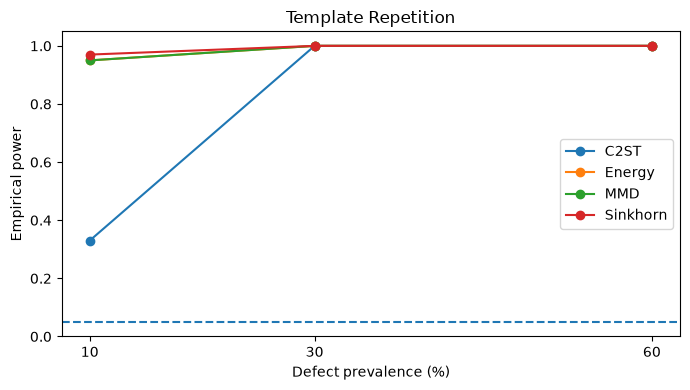

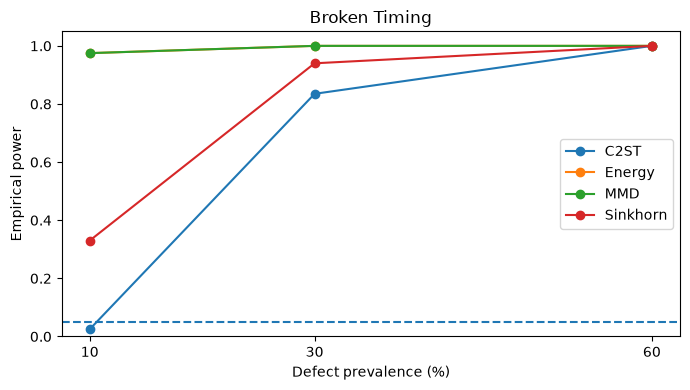

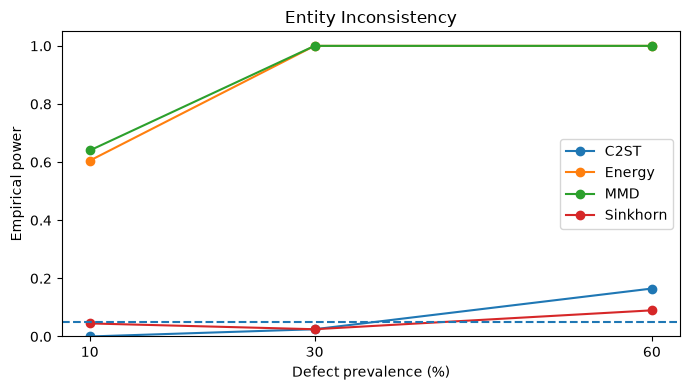

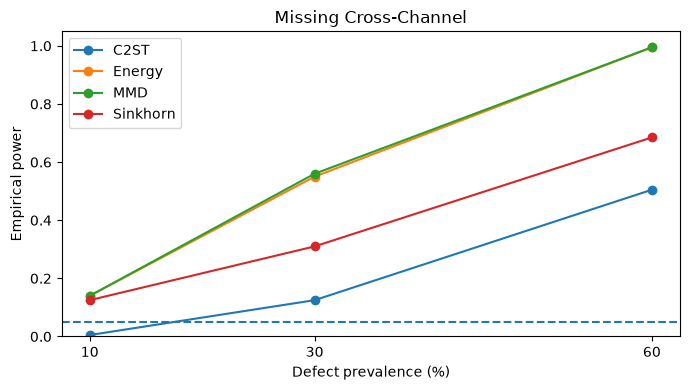

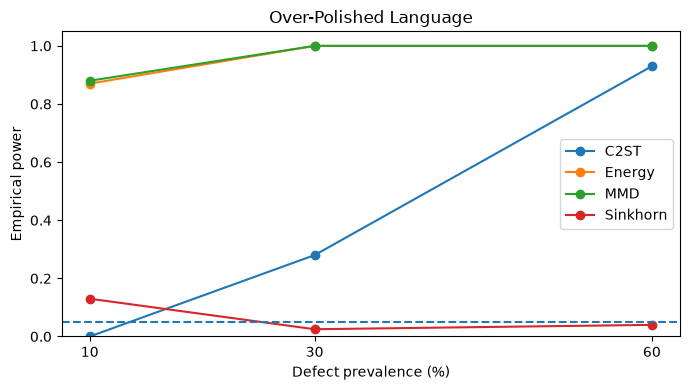

In [35]:
for defect in DEFECTS:
    d=power.loc[power["defect"]==defect]
    plt.figure(figsize=(7,4))
    for metric in METRICS:
        q=d.loc[d["metric"]==metric].sort_values("severity")
        plt.plot(q["severity"]*100,q["power"],marker="o",label=metric)
    plt.axhline(.05,linestyle="--")
    plt.xlabel("Defect prevalence (%)"); plt.ylabel("Empirical power"); plt.title(defect)
    plt.xticks([10,30,60]); plt.ylim(0,1.05); plt.legend(); plt.tight_layout(); plt.show()

##### precision and recall plots 

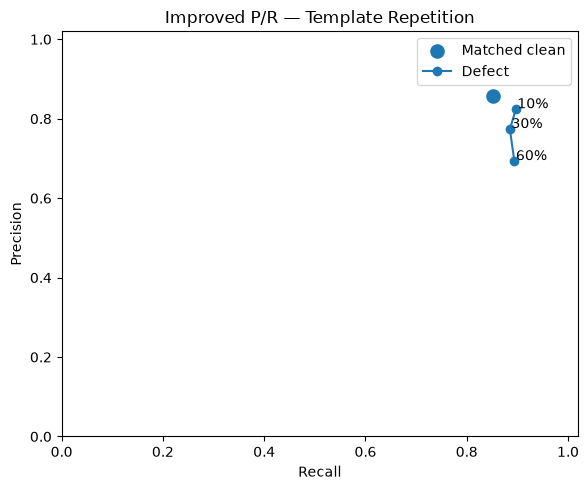

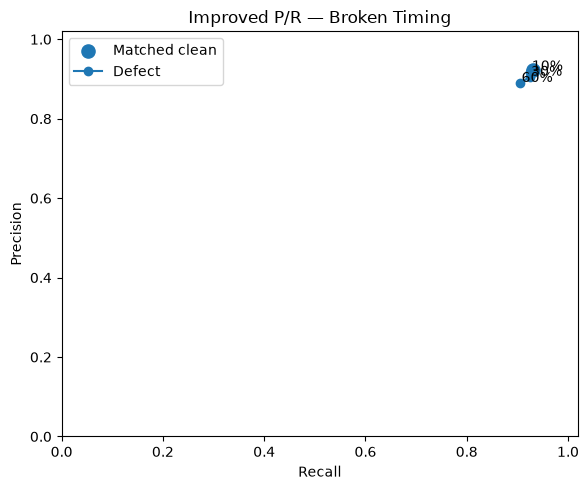

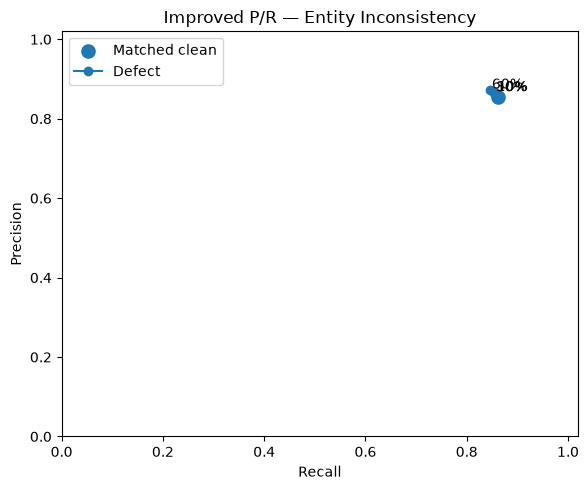

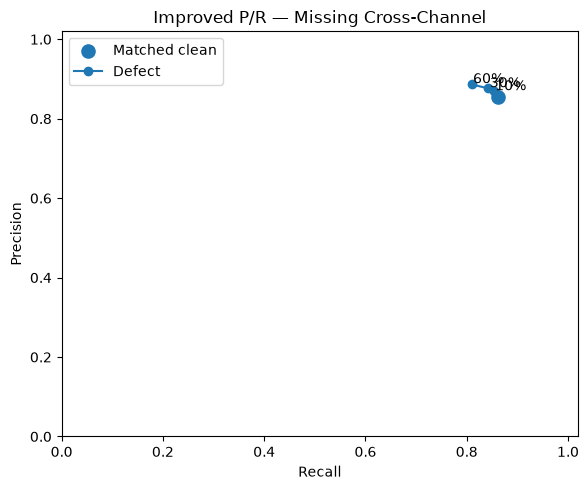

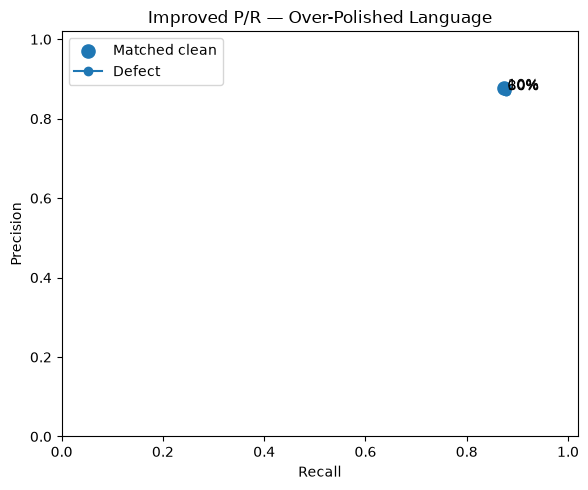

In [36]:
for defect in DEFECTS:
    d=ipr.loc[ipr["defect"]==defect].sort_values("severity")
    plt.figure(figsize=(6,5))
    plt.scatter(d["matched_recall"].iloc[0],d["matched_precision"].iloc[0],s=90,label="Matched clean")
    plt.plot(d["mean_recall"],d["mean_precision"],marker="o",label="Defect")
    for _,r in d.iterrows(): plt.text(r["mean_recall"]+.003,r["mean_precision"]+.003,f"{r['severity']:.0%}")
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"Improved P/R — {defect}")
    plt.xlim(0,1.02); plt.ylim(0,1.02); plt.legend(); plt.tight_layout(); plt.show()

#### sinkhorn observed minus null trajectories 


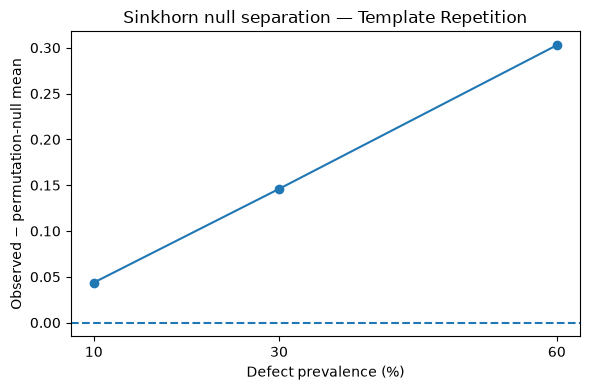

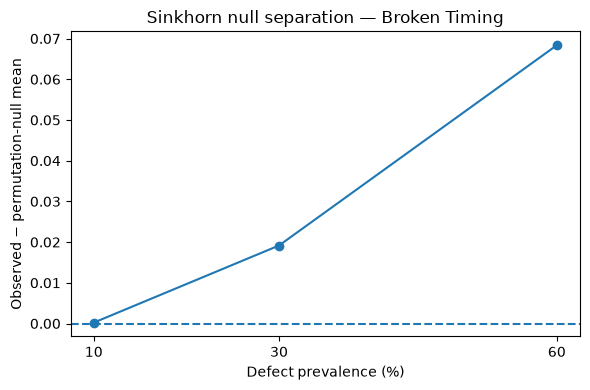

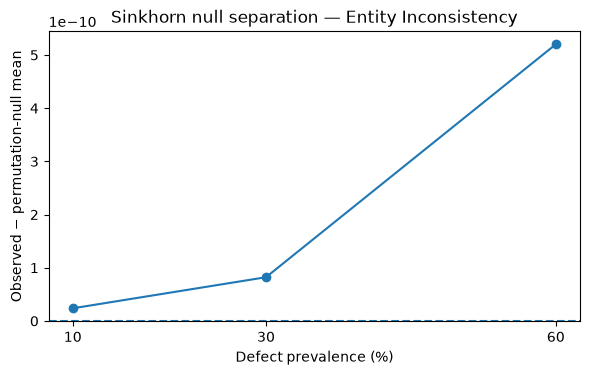

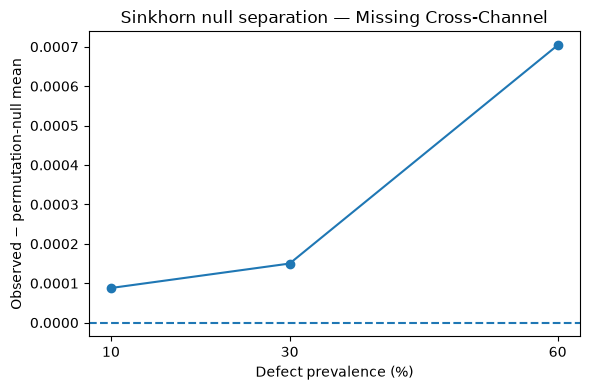

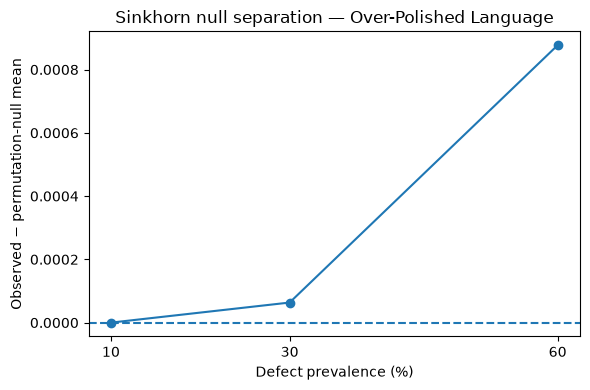

In [37]:
for defect in DEFECTS:
    d=sink_gap.loc[sink_gap["defect"]==defect].sort_values("severity")
    plt.figure(figsize=(6,4))
    plt.plot(d["severity"]*100,d["sinkhorn_obs_minus_null"],marker="o")
    plt.axhline(0,linestyle="--")
    plt.xlabel("Defect prevalence (%)"); plt.ylabel("Observed − permutation-null mean")
    plt.title(f"Sinkhorn null separation — {defect}")
    plt.xticks([10,30,60]); plt.tight_layout(); plt.show()

#### descriptive behavior matrix

In [38]:
def behavior(x):
    if x<.10: return "near-null"
    if x<.50: return "low"
    if x<.90: return "moderate"
    return "high"

behavior_long=power.copy()
behavior_long["response"]=behavior_long["power"].map(behavior)
behavior_matrix=behavior_long.pivot(index=["defect","severity"],columns="metric",values="response").reset_index()
display(behavior_matrix)

metric,defect,severity,C2ST,Energy,MMD,Sinkhorn
0,Broken Timing,0.1,near-null,high,high,low
1,Broken Timing,0.3,moderate,high,high,high
2,Broken Timing,0.6,high,high,high,high
3,Entity Inconsistency,0.1,near-null,moderate,moderate,near-null
4,Entity Inconsistency,0.3,near-null,high,high,near-null
5,Entity Inconsistency,0.6,low,high,high,near-null
6,Missing Cross-Channel,0.1,near-null,low,low,low
7,Missing Cross-Channel,0.3,low,moderate,moderate,low
8,Missing Cross-Channel,0.6,moderate,high,high,moderate
9,Over-Polished Language,0.1,near-null,moderate,moderate,low


#### cross metric interpretation table 

In [39]:
metric_roles=pd.DataFrame([
    ["C2ST","Hypothesis test","Classifier separability","Sensitive to classifier capacity"],
    ["MMD","Hypothesis test","Kernel distribution discrepancy","Depends on representation and frozen kernel scale"],
    ["Energy","Hypothesis test","Distance-based distribution discrepancy","Can detect broad distributional changes"],
    ["Sinkhorn","Hypothesis test","Regularized transport discrepancy relative to paired permutation null","Observed transport magnitude alone is not sufficient"],
    ["Representation displacement","Descriptive","Per-unit movement in representation space","Raw magnitudes are not comparable across representations"],
    ["Improved Precision","Descriptive support","Defective mass inside estimated clean support","Depends on finite-sample k-NN geometry"],
    ["Improved Recall","Descriptive coverage","Clean support covered by defective distribution","Depends on finite-sample k-NN geometry"]
],columns=["diagnostic","type","primary_question","important_limitation"])

display(metric_roles)

,diagnostic,type,primary_question,important_limitation
0,C2ST,Hypothesis test,Classifier separability,Sensitive to classifier capacity
1,MMD,Hypothesis test,Kernel distribution discrepancy,Depends on representation and frozen kernel scale
2,Energy,Hypothesis test,Distance-based distribution discrepancy,Can detect broad distributional changes
3,Sinkhorn,Hypothesis test,Regularized transport discrepancy relative to ...,Observed transport magnitude alone is not suff...
4,Representation displacement,Descriptive,Per-unit movement in representation space,Raw magnitudes are not comparable across repre...
5,Improved Precision,Descriptive support,Defective mass inside estimated clean support,Depends on finite-sample k-NN geometry
6,Improved Recall,Descriptive coverage,Clean support covered by defective distribution,Depends on finite-sample k-NN geometry


In [41]:
# save 
power.to_csv(OUT/"week7_power_long.csv",index=False)
power_matrix.to_csv(OUT/"week7_power_matrix.csv",index=False)
null_table.to_csv(OUT/"week7_typeI_calibration.csv",index=False)
displacement.to_csv(OUT/"week7_representation_displacement.csv",index=False)
sink_gap.to_csv(OUT/"week7_sinkhorn_observed_minus_null.csv",index=False)
ipr.to_csv(OUT/"week7_improved_precision_recall.csv",index=False)
master.to_csv(OUT/"week7_master_matrix.csv",index=False)
master_compact.to_csv(OUT/"week7_master_matrix_compact.csv",index=False)
blind_spots.to_csv(OUT/"week7_blind_spots_negative_findings.csv",index=False)
behavior_matrix.to_csv(OUT/"week7_detection_behavior.csv",index=False)
metric_roles.to_csv(OUT/"week7_metric_roles.csv",index=False)

print("Saved to:",OUT)

Saved to: /Users/jessica/fidelity-metric-lab/results/week7/comparison


# Final Week 7 interpretation framework

The five formal defects demonstrate that fidelity diagnostic behavior cannot be explained by defect severity alone.

The observed response is better understood as an interaction between:

$$\text{Defect}
\times
\text{Representation}
\times
\text{Metric}
\times
\text{Test design}.
$$

Several distinctions are essential.

First, strong individual representation displacement does not automatically imply strong statistical detectability, and small displacement does not imply that a distribution-level test will be insensitive.

Second, C2ST, MMD, Energy, and Sinkhorn do not measure the same discrepancy. A defect can therefore be strongly detected by one test and remain nearly invisible to another.

Third, the raw Sinkhorn transport statistic must be interpreted relative to its paired permutation null. The observed-minus-null quantity provides an important explanation for cases in which the absolute statistic changes but rejection power remains weak.

Fourth, Improved Precision and Recall answer a different question from the hypothesis tests. A distribution can be statistically distinguishable while remaining largely inside the same estimated support, as observed for several semantic defects.

Finally, negative findings are part of the result rather than failures to be removed. Linear C2ST blindness, paired Sinkhorn invariance, stable support under detectable semantic changes, and the unexpected Template Repetition geometry all identify specific limitations of the corresponding diagnostic configuration.

Week 7 therefore does not produce a single best fidelity metric.

It produces a map of complementary sensitivities and blind spots.